# Bank Marketing Analysis 

**Dataset:** [Bank Marketing Dataset - Kaggle]("https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset")  
**Tool:** Python (pandas, plotnine, seaborn, matplotlib)  


#### Imports

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import janitor
from plotnine import *
import warnings
import missingno as msno

import importlib
import matplotlib.pyplot as plt
%matplotlib inline
from scripts.profiling import *
from IPython.display import display

warnings.filterwarnings('ignore')

In [2]:
bank_raw = pd.read_csv('../data/raw/bank.csv')


#### Data viewing and interrogation

In [3]:
bank_raw.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


*Check data types*

In [4]:
bank_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [6]:
bank_raw.dtypes

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
deposit      object
dtype: object

In [12]:
bank_raw.shape

(11162, 17)

In [ ]:
#summary statistics
bank_raw.describe(include='all').round(2)

,age,balance,day,duration,campaign,pdays,previous
count,11162.00,11162.00,11162.00,11162.00,11162.00,11162.00,11162.00
mean,41.23,1528.54,15.66,371.99,2.51,51.33,0.83
std,11.91,3225.41,8.42,347.13,2.72,108.76,2.29
min,18.00,-6847.00,1.00,2.00,1.00,-1.00,0.00
25%,32.00,122.00,8.00,138.00,1.00,-1.00,0.00
50%,39.00,550.00,15.00,255.00,2.00,-1.00,0.00
75%,49.00,1708.00,22.00,496.00,3.00,20.75,1.00
max,95.00,81204.00,31.00,3881.00,63.00,854.00,58.00


*Check for missing values*

In [10]:
bank_raw.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

*Check for duplicates*

In [11]:
bank_raw.duplicated().sum()

np.int64(0)

*Look for hidden blanks in text columns*
> List of different values in the column and how many times each appear

In [6]:
bank_raw['contact'].value_counts()

contact
cellular     8042
unknown      2346
telephone     774
Name: count, dtype: int64

In [8]:
bank_raw['poutcome'].value_counts()

poutcome
unknown    8326
failure    1228
success    1071
other       537
Name: count, dtype: int64

*What does "unknown" in poutcome actually mean?
> For everyone whose poutcome is "unknown", how many times were they contacted before?

In [5]:
bank_raw[bank_raw['poutcome']=='unknown']['previous'].describe()

count    8326.000000
mean        0.000360
std         0.024505
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         2.000000
Name: previous, dtype: float64

A total of 8,326 unknowns   
conclusion: "unknown" here means the customer has no previous campaign report

*Looking at the shape of the numerical columns*

--- Skewness (numeric columns) ---

balance
  Skewness : 8.2246
  Direction: Right (positive)
  Meaning  : Highly right-skewed -> most values low with high outliers. Consider log transformation.

previous
  Skewness : 7.3353
  Direction: Right (positive)
  Meaning  : Highly right-skewed -> most values low with high outliers. Consider log transformation.

campaign
  Skewness : 5.5456
  Direction: Right (positive)
  Meaning  : Highly right-skewed -> most values low with high outliers. Consider log transformation.

pdays
  Skewness : 2.4500
  Direction: Right (positive)
  Meaning  : Highly right-skewed -> most values low with high outliers. Consider log transformation.

duration
  Skewness : 2.1437
  Direction: Right (positive)
  Meaning  : Highly right-skewed -> most values low with high outliers. Consider log transformation.

age
  Skewness : 0.8628
  Direction: Right (positive)
  Meaning  : Moderately right-skewed -> slight positive tail. Worth noting before modelling.

day
  Skewness 

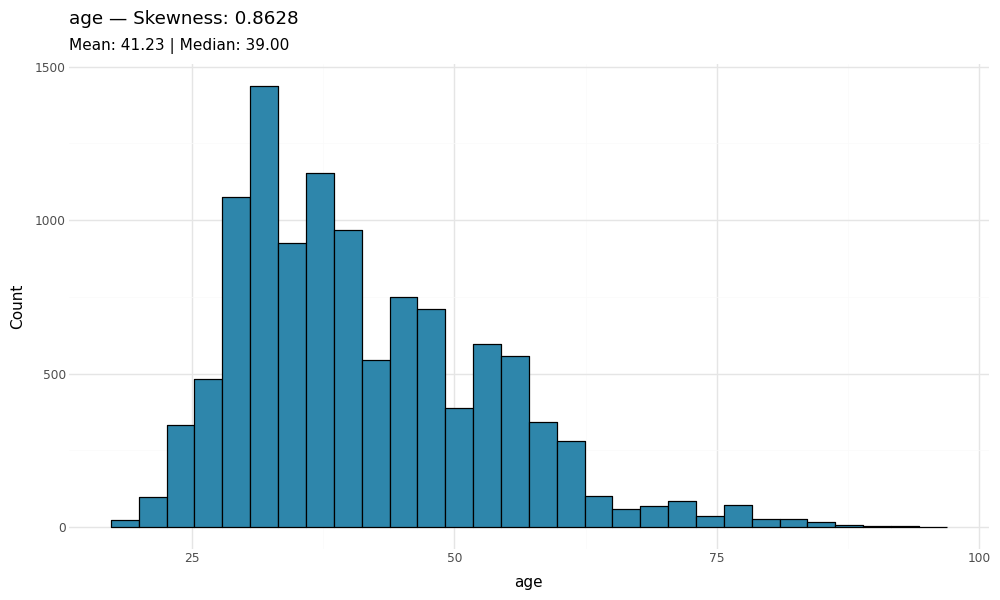

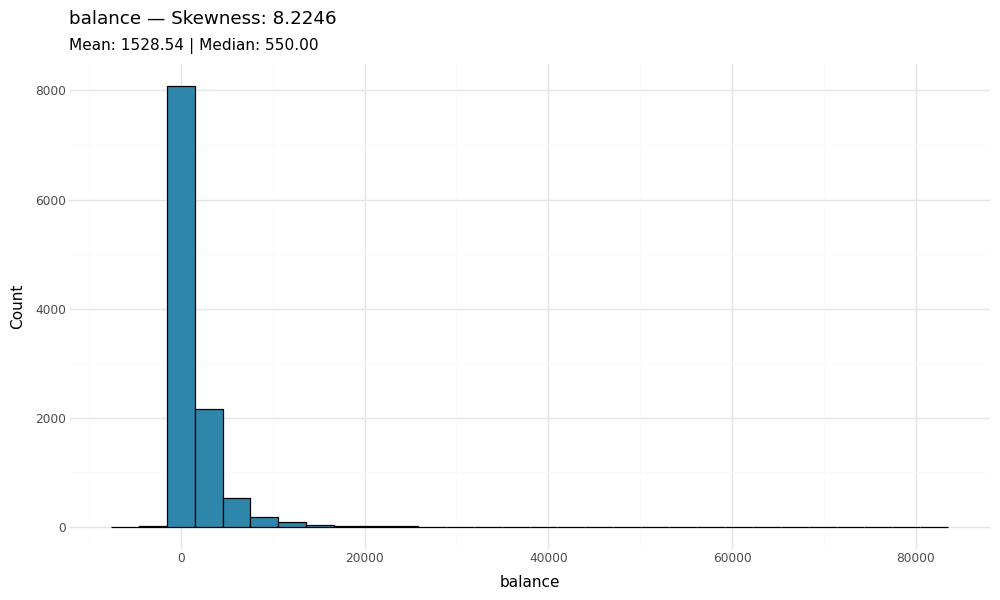

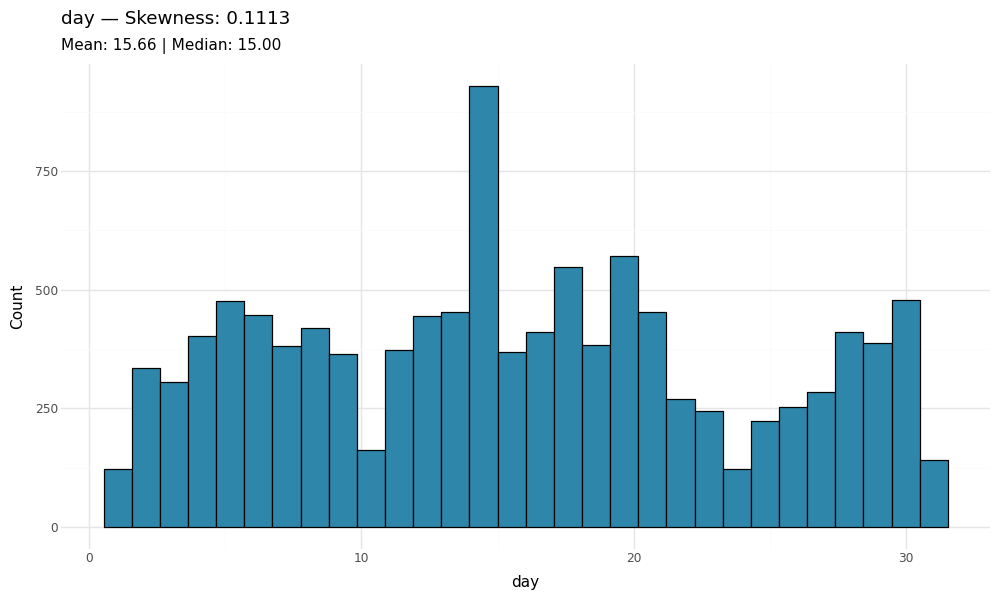

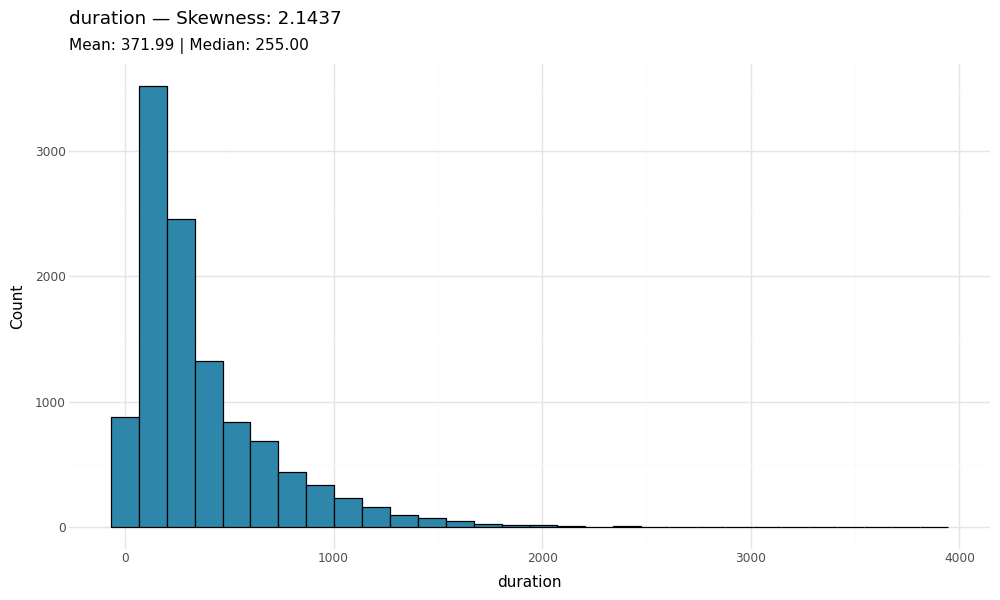

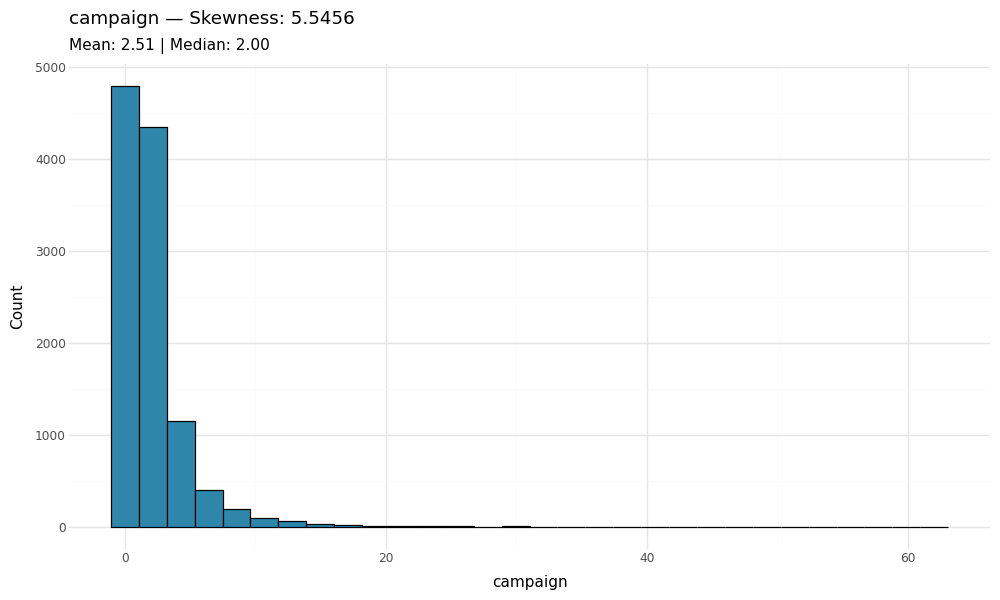

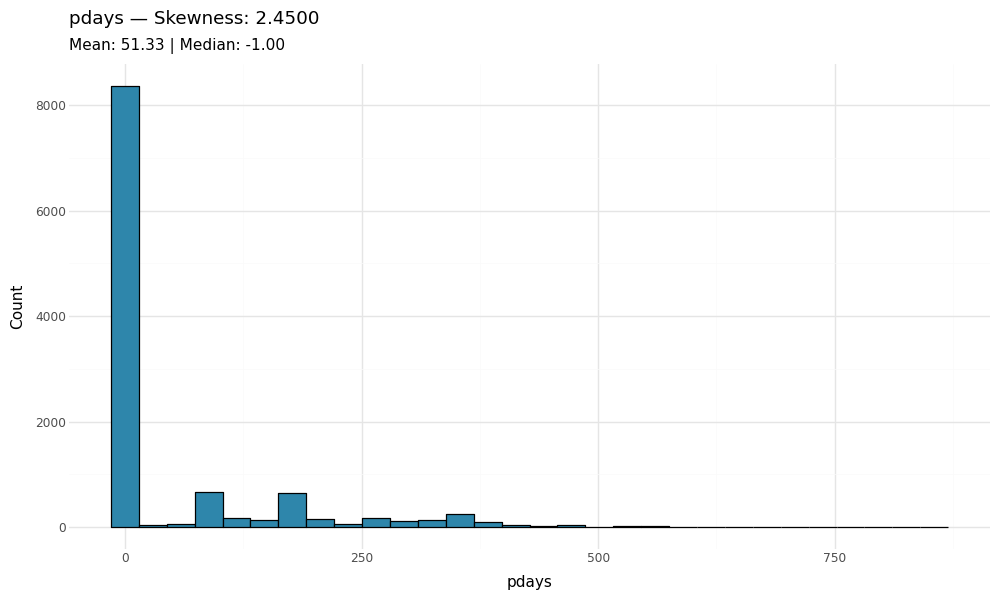

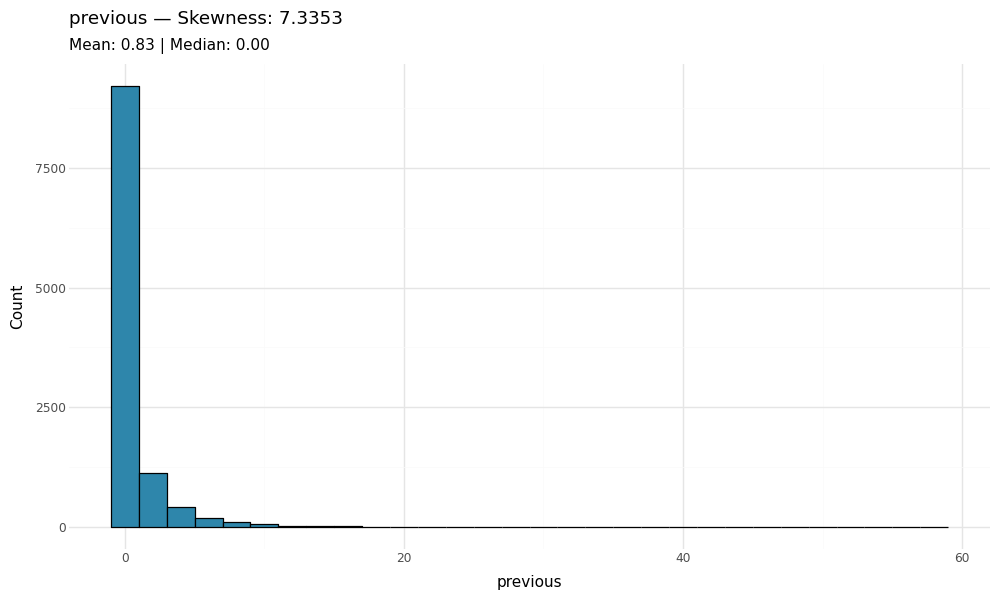

balance     8.224619
previous    7.335298
campaign    5.545578
pdays       2.449986
duration    2.143695
age         0.862780
day         0.111330
dtype: float64

In [ ]:
check_skewness(bank_raw, plot=True)

**Check for extreme values**   
Flag values that sit far outside the normal range

In [ ]:
detect_outliers(bank_raw, 'balance')

Column   : balance
Method   : IQR fence: [-2257.00, 4087.00]
Outliers : 1,055 rows (9.45% of data)
Min value: -6847.00
Max value: 81204.00


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
9,28,services,single,secondary,no,5090,yes,no,unknown,6,may,1297,3,-1,0,unknown,yes
60,51,blue-collar,married,secondary,no,7180,yes,no,unknown,14,may,927,1,-1,0,unknown,yes
61,41,blue-collar,divorced,secondary,no,5291,yes,no,unknown,14,may,1423,3,-1,0,unknown,yes
69,44,technician,married,tertiary,no,4580,yes,no,unknown,15,may,911,2,-1,0,unknown,yes
71,29,management,married,tertiary,no,10576,no,no,unknown,15,may,1224,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11073,34,blue-collar,married,primary,no,6718,no,no,cellular,13,jan,278,4,97,1,other,no
11077,54,retired,divorced,tertiary,no,6102,yes,yes,unknown,21,may,86,6,-1,0,unknown,no
11085,60,technician,married,primary,no,4243,yes,no,cellular,4,feb,387,1,251,1,failure,no
11086,42,admin.,married,secondary,no,6445,yes,no,unknown,2,jun,20,8,-1,0,unknown,no


In [ ]:
detect_outliers(bank_raw, 'campaign')

Column   : campaign
Method   : IQR fence: [-2.00, 6.00]
Outliers : 601 rows (5.38% of data)
Min value: 7.00
Max value: 63.00


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
125,35,blue-collar,married,primary,no,994,yes,no,unknown,23,may,1349,8,-1,0,unknown,yes
135,44,technician,divorced,secondary,no,1262,yes,no,unknown,26,may,788,11,-1,0,unknown,yes
163,51,entrepreneur,married,unknown,no,606,yes,no,unknown,28,may,560,9,-1,0,unknown,yes
186,35,technician,divorced,secondary,no,5724,yes,no,unknown,30,may,691,10,-1,0,unknown,yes
187,34,technician,divorced,secondary,no,1451,yes,no,unknown,30,may,1097,15,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11057,31,management,divorced,tertiary,no,-547,yes,yes,cellular,31,jul,101,10,-1,0,unknown,no
11074,37,management,married,tertiary,no,21,no,no,cellular,21,aug,50,12,-1,0,unknown,no
11086,42,admin.,married,secondary,no,6445,yes,no,unknown,2,jun,20,8,-1,0,unknown,no
11139,30,self-employed,single,tertiary,no,2593,no,no,unknown,27,may,662,7,-1,0,unknown,no


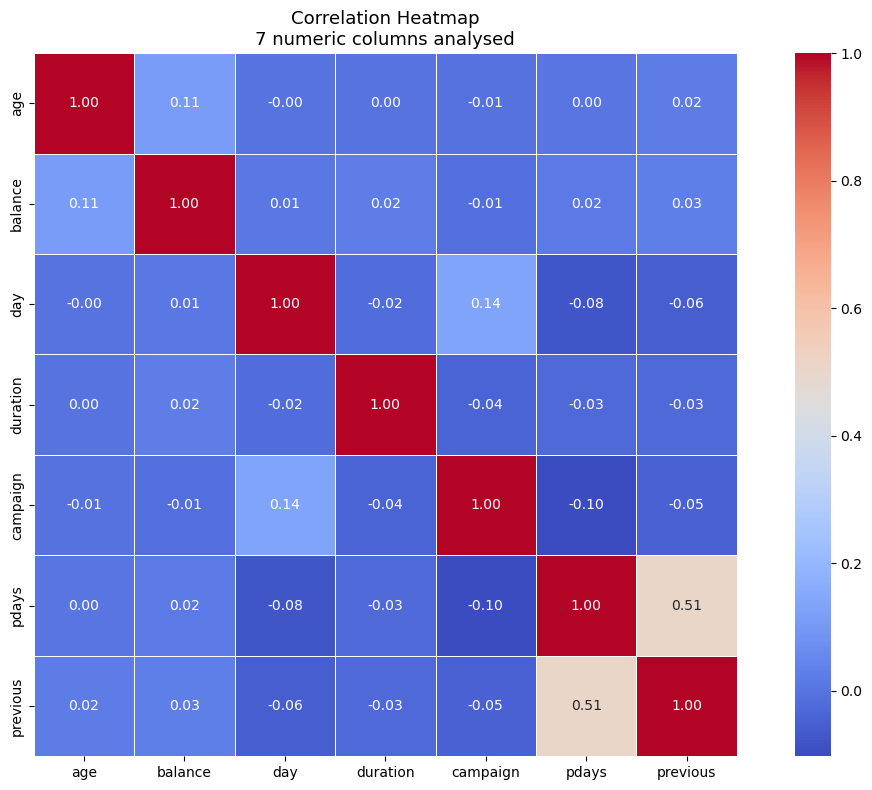

,age,balance,day,duration,campaign,pdays,previous
age,1.000000,0.112300,-0.000762,0.000189,-0.005278,0.002774,0.020169
balance,0.112300,1.000000,0.010467,0.022436,-0.013894,0.017411,0.030805
day,-0.000762,0.010467,1.000000,-0.018511,0.137007,-0.077232,-0.058981
duration,0.000189,0.022436,-0.018511,1.000000,-0.041557,-0.027392,-0.026716
campaign,-0.005278,-0.013894,0.137007,-0.041557,1.000000,-0.102726,-0.049699
pdays,0.002774,0.017411,-0.077232,-0.027392,-0.102726,1.000000,0.507272
previous,0.020169,0.030805,-0.058981,-0.026716,-0.049699,0.507272,1.000000


In [ ]:
plot_correlation(bank_raw, title='Correlation Heatmap', subtitle=None,
                     figsize=(12, 8), cmap='coolwarm')